In [6]:

# a. Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

np.random.seed(42)
tf.random.set_seed(42)

# b. Load credit card dataset
df = pd.read_csv('creditcard.csv')

print("Dataset shape:", df.shape)
print("\nClass distribution:")
print(df['Class'].value_counts())

# Separate features and labels
labels = df['Class'].values
features = df.drop(columns=['Time', 'Class']).values

# Separate normal and fraudulent transactions
normal = features[labels == 0]
fraud = features[labels == 1]

# c. Split normal transactions into training and testing
X_train, X_test_normal = train_test_split(
    normal, test_size=0.2, random_state=42
)

# Normalize using only normal training data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test_normal = scaler.transform(X_test_normal)
X_test_fraud = scaler.transform(fraud)

print("\nTraining data:", X_train.shape)
print("Normal test data:", X_test_normal.shape)
print("Fraud test data:", X_test_fraud.shape)

# d. Build Autoencoder
input_dim = X_train.shape[1]

autoencoder = tf.keras.Sequential([
    layers.Input(shape=(input_dim,)),

    # Encoder - compress transaction features
    layers.Dense(32, activation='relu'),
    layers.Dense(16, activation='relu'),
    layers.Dense(8, activation='relu'),

    # Decoder - reconstruct the original features
    layers.Dense(16, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(input_dim, activation='linear')
])

# e. Compile the model
autoencoder.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

# f. Train only on normal transactions
history = autoencoder.fit(
    X_train, X_train,
    epochs=30,
    batch_size=256,
    validation_data=(X_test_normal, X_test_normal),
    shuffle=True,
    verbose=0
)

print("\nTraining completed.")
print("Final Training Loss:", round(history.history['loss'][-1], 4))
print("Final Validation Loss:", round(history.history['val_loss'][-1], 4))


Dataset shape: (284807, 31)

Class distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Training data: (227452, 29)
Normal test data: (56863, 29)
Fraud test data: (492, 29)

Training completed.
Final Training Loss: 0.2177
Final Validation Loss: 0.2174


In [7]:

# Calculate reconstruction error on normal training data
train_recon = autoencoder.predict(X_train, verbose=0)
train_error = np.mean(np.square(X_train - train_recon), axis=1)

# Set threshold using 99th percentile of normal errors
threshold = np.percentile(train_error, 99)

# Reconstruct normal and fraudulent test transactions
normal_recon = autoencoder.predict(X_test_normal, verbose=0)
fraud_recon = autoencoder.predict(X_test_fraud, verbose=0)

# Calculate reconstruction errors
normal_error = np.mean(np.square(X_test_normal - normal_recon), axis=1)
fraud_error = np.mean(np.square(X_test_fraud - fraud_recon), axis=1)

# Combine actual labels and reconstruction errors
y_true = np.concatenate([
    np.zeros(len(normal_error)),
    np.ones(len(fraud_error))
])

y_error = np.concatenate([normal_error, fraud_error])

# Error above threshold = Fraud
y_pred = (y_error > threshold).astype(int)

# Calculate evaluation metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

cm = confusion_matrix(y_true, y_pred)

# Display results in a simple text format
print("\n========== ANOMALY DETECTION RESULTS ==========")
print("Anomaly Threshold :", round(threshold, 4))
print("Accuracy          :", round(accuracy * 100, 2), "%")
print("Precision         :", round(precision * 100, 2), "%")
print("Fraud Recall      :", round(recall * 100, 2), "%")
print("F1 Score          :", round(f1, 4))

print("\n========== CONFUSION MATRIX ==========")
print("                 Predicted")
print("                 Normal   Fraud")
print("Actual Normal   ", cm[0])
print("Actual Fraud    ", cm[1])

print("\n========== RECONSTRUCTION ERRORS ==========")
print("Average Normal Error:", round(normal_error.mean(), 4))
print("Average Fraud Error :", round(fraud_error.mean(), 4))

print("\nFirst 5 Normal Transaction Errors:")
print(np.round(normal_error[:5], 4))

print("\nFirst 5 Fraud Transaction Errors:")
print(np.round(fraud_error[:5], 4))

# Display five detected fraudulent transactions
print("\n========== DETECTED FRAUD TRANSACTIONS ==========")

detected = np.where(fraud_error > threshold)[0]

for i in detected[:5]:
    print("Transaction:", i + 1,
          "| Error:", round(fraud_error[i], 4),
          "| Result: Fraud")

print("\nNormal transactions correctly accepted:",
      np.sum(normal_error <= threshold), "/", len(normal_error))

print("Fraud transactions correctly detected:",
      len(detected), "/", len(fraud_error))



========== ANOMALY DETECTION RESULTS ==========
Anomaly Threshold : 1.2949
Accuracy          : 98.78 %
Precision         : 39.6 %
Fraud Recall      : 80.89 %
F1 Score          : 0.5317

========== CONFUSION MATRIX ==========
                 Predicted
                 Normal   Fraud
Actual Normal    [56256   607]
Actual Fraud     [ 94 398]

========== RECONSTRUCTION ERRORS ==========
Average Normal Error: 0.2174
Average Fraud Error : 21.4766

First 5 Normal Transaction Errors:
[0.0731 0.0827 0.1618 0.1105 0.2182]

First 5 Fraud Transaction Errors:
[ 3.3559  0.5507  3.6195 20.4761  1.1916]

========== DETECTED FRAUD TRANSACTIONS ==========
Transaction: 1 | Error: 3.3559 | Result: Fraud
Transaction: 3 | Error: 3.6195 | Result: Fraud
Transaction: 4 | Error: 20.4761 | Result: Fraud
Transaction: 6 | Error: 10.4576 | Result: Fraud
Transaction: 7 | Error: 10.4594 | Result: Fraud

Normal transactions correctly accepted: 56256 / 56863
Fraud transactions correctly detected: 398 / 492


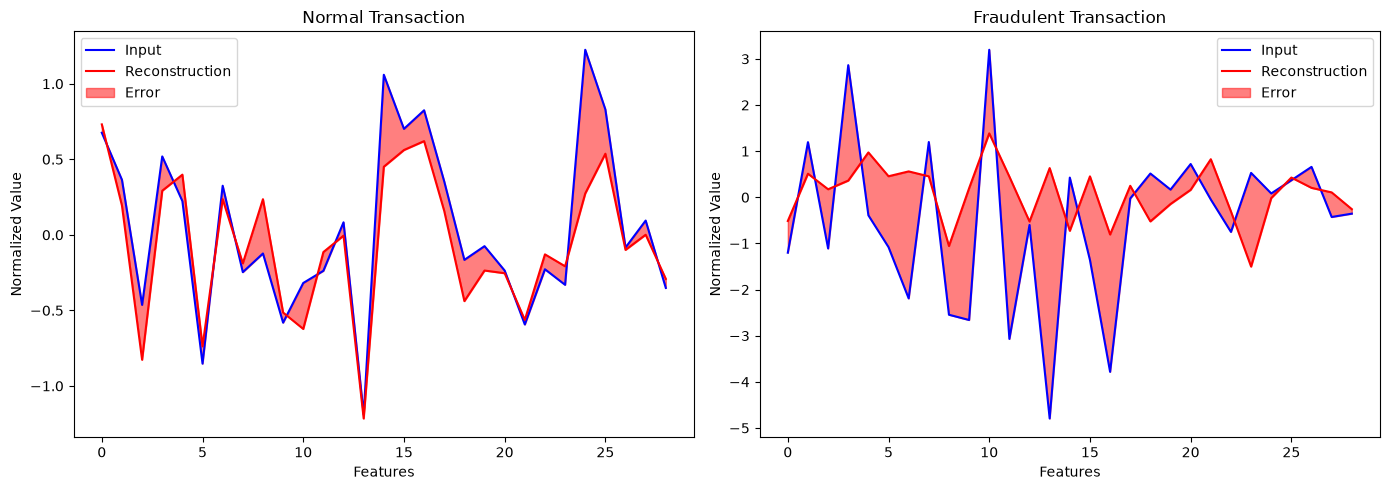

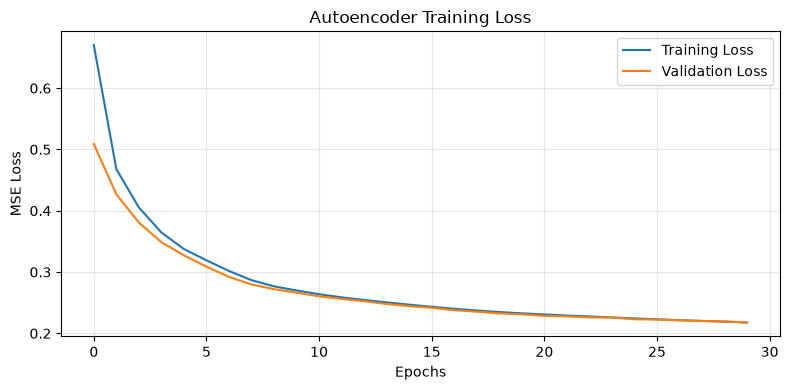

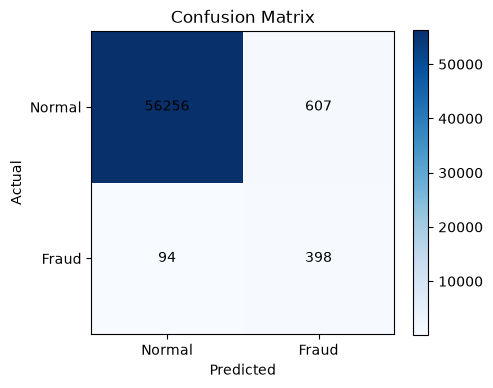

In [9]:
# 1. Classic Autoencoder Anomaly Detection Graph

import matplotlib.pyplot as plt
import numpy as np

# Select one normal and one fraud transaction
normal = X_test_normal[0:1]
fraud = X_test_fraud[0:1]

# FIX: Changed 'model' to 'autoencoder'
normal_reconstructed = autoencoder.predict(normal, verbose=0)
fraud_reconstructed = autoencoder.predict(fraud, verbose=0)

# Plot input and reconstruction
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, original, reconstructed, label in [
    (axes[0], normal[0], normal_reconstructed[0], "Normal Transaction"),
    (axes[1], fraud[0], fraud_reconstructed[0], "Fraudulent Transaction")
]:
    features = np.arange(len(original))

    ax.plot(features, original, color='blue', label='Input')
    ax.plot(features, reconstructed, color='red', label='Reconstruction')
    ax.fill_between(features, original, reconstructed,
                    color='red', alpha=0.5, label='Error')

    ax.set_title(label)
    ax.set_xlabel("Features")
    ax.set_ylabel("Normalized Value")
    ax.legend()

plt.tight_layout()
plt.show()

# 2. Training and Validation Loss Graph
plt.figure(figsize=(8, 4))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('MSE Loss')
plt.title('Autoencoder Training Loss')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# 3. Confusion Matrix Graph
plt.figure(figsize=(5, 4))

plt.imshow(cm, cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.xticks([0, 1], ['Normal', 'Fraud'])
plt.yticks([0, 1], ['Normal', 'Fraud'])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j],
                 ha='center', va='center')

plt.colorbar()
plt.tight_layout()
plt.show()